# TextCNN

In [1]:
import copy
import itertools
import json
import time
from collections import Counter
from pathlib import Path
from pathlib import Path
from google.colab import drive
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, auc, classification_report, confusion_matrix, roc_curve
from torch.utils.data import DataLoader, TensorDataset

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

DRIVE_DIR = Path("/content/drive/MyDrive/NLP")
DRIVE_DIR.mkdir(parents=True, exist_ok=True)

DATASET_PATH = str(DRIVE_DIR / "merged_dataset(1).txt")
RESULTS_DIR = DRIVE_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODEL_SAVE_PATH = str(RESULTS_DIR / "best_model.bin")
PRE_TRAINED_MODEL_NAME = "roberta-base"

device = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = device == "cuda"
print(f"Using device: {device}")
torch.manual_seed(42)
np.random.seed(42)
if device == "cuda":
    torch.cuda.manual_seed_all(42)

Mounted at /content/drive
Using device: cuda


## Nạp dữ liệu và chia theo chủ đề

In [2]:
df = pd.read_csv(DATASET_PATH)
df = df.sample(frac=1, random_state=42).reset_index(drop=True)
df.dropna(subset=["text"], inplace=True)
df["text"] = df["text"].astype(str)

train_sources = [
    "HC3_reddit_eli5",
    "HC3_finance",
    "DAIGT_v2_Distance learning",
    "DAIGT_v2_Seeking multiple opinions",
    "HC3_open_qa",
]
val_sources = [
    "DAIGT_v2_Car-free cities",
    "DAIGT_v2_Does the electoral college work?",
    "DAIGT_v2_Facial action coding system",
    "DAIGT_v2_Mandatory extracurricular activities",
    "DAIGT_v2_Summer projects",
    "HC3_medicine",
    "DAIGT_v2_Driverless cars",
    "DAIGT_v2_Exploring Venus",
]
test_sources = [
    "DAIGT_v2_Cell phones at school",
    "DAIGT_v2_Grades for extracurricular activities",
    "DAIGT_v2_Community service",
    'DAIGT_v2_"A Cowboy Who Rode the Waves"',
    "DAIGT_v2_The Face on Mars",
    "HC3_wiki_csai",
    "DAIGT_v2_Phones and driving",
]

missing = set(train_sources + val_sources + test_sources) - set(df["source"].unique())
assert not missing, f"Không tìm thấy các nguồn: {missing}"

train_df = df[df["source"].isin(train_sources)]
val_df = df[df["source"].isin(val_sources)]
test_df = df[df["source"].isin(test_sources)]

X_train, y_train = train_df["text"].values, train_df["label"].values
X_val, y_val = val_df["text"].values, val_df["label"].values
X_test, y_test = test_df["text"].values, test_df["label"].values

print(f"Tổng số mẫu:  {len(df)}")
print(f"Tập train:    {len(X_train)} ({len(X_train) / len(df):.1%})")
print(f"Tập val:      {len(X_val)} ({len(X_val) / len(df):.1%})")
print(f"Tập test:     {len(X_test)} ({len(X_test) / len(df):.1%})")

Tổng số mẫu:  124195
Tập train:    85897 (69.2%)
Tập val:      24987 (20.1%)
Tập test:     13311 (10.7%)


## Tiền xử lý (từ điển và padding)

In [3]:
class TextTokenizer:
    def __init__(self, max_words=30000, max_len=600):
        self.max_words = max_words
        self.max_len = max_len
        self.word_index = {}
        self.vocab_size = 0

    def fit(self, texts):
        counter = Counter()
        for text in texts:
            counter.update(text.lower().split())
        most_common = counter.most_common(self.max_words - 1)
        self.word_index = {word: i + 1 for i, (word, _) in enumerate(most_common)}
        self.vocab_size = len(self.word_index) + 1
        print(f"Vocabulary size: {self.vocab_size}")

    def transform(self, texts):
        sequences = np.zeros((len(texts), self.max_len), dtype=np.int64)
        for i, text in enumerate(texts):
            ids = [self.word_index.get(w, 0) for w in text.lower().split()][: self.max_len]
            sequences[i, : len(ids)] = ids
        return sequences

tokenizer = TextTokenizer(max_words=30000, max_len=600)
tokenizer.fit(X_train)                       # từ điển chỉ học từ tập train
X_train_seq = tokenizer.transform(X_train)
X_val_seq = tokenizer.transform(X_val)
X_test_seq = tokenizer.transform(X_test)

train_data = TensorDataset(torch.from_numpy(X_train_seq), torch.FloatTensor(y_train))
val_data = TensorDataset(torch.from_numpy(X_val_seq), torch.FloatTensor(y_val))
test_data = TensorDataset(torch.from_numpy(X_test_seq), torch.FloatTensor(y_test))

Vocabulary size: 30000


## Mô hình TextCNN

In [4]:
class TextCNN(nn.Module):
    def __init__(self, vocab_size, embedding_dim, num_filters, dropout_rate, kernel_sizes=(3, 5, 7)):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(embedding_dim, num_filters, k) for k in kernel_sizes])
        self.dropout = nn.Dropout(dropout_rate)
        self.fc1 = nn.Linear(num_filters * len(kernel_sizes), 64)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        embedded = self.embedding(x).transpose(1, 2)                      # (batch, embedding, length)
        pooled = [torch.relu(conv(embedded)).max(dim=2).values for conv in self.convs]
        x = self.dropout(torch.cat(pooled, dim=1))
        x = self.dropout(self.relu(self.fc1(x)))
        return self.fc2(x)

def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=15, patience=3):
    best_val_acc = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    patience_counter = 0
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device).unsqueeze(1)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
            correct += ((torch.sigmoid(outputs) > 0.5).float() == labels).sum().item()
            total += labels.size(0)
        history["train_loss"].append(running_loss / total)
        history["train_acc"].append(correct / total)

        model.eval()
        val_loss_sum, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device).unsqueeze(1)
                outputs = model(inputs)
                val_loss_sum += criterion(outputs, labels).item() * inputs.size(0)
                val_correct += ((torch.sigmoid(outputs) > 0.5).float() == labels).sum().item()
                val_total += labels.size(0)
        val_loss, val_acc = val_loss_sum / val_total, val_correct / val_total
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch + 1}/{epochs} | Train Loss: {history['train_loss'][-1]:.4f} Acc: {history['train_acc'][-1]:.4f} "
              f"| Val Loss: {val_loss:.4f} Acc: {val_acc:.4f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("Early stopping.")
                break

    model.load_state_dict(best_model_wts)
    return model, history, best_val_acc

## Tìm kiếm siêu tham số (grid search)

In [5]:
param_grid = {
    "num_filters": [64, 128, 256],
    "dropout_rate": [0.2, 0.3, 0.5],
    "batch_size": [128, 256],
    "learning_rate": [0.0005, 0.001],
}
combinations = [dict(zip(param_grid.keys(), v)) for v in itertools.product(*param_grid.values())]

best_overall_acc, best_config, best_model_final, best_history_final = 0.0, {}, None, None
results_log = []
grid_start_time = time.time()

for i, params in enumerate(combinations):
    print(f"\n--- Config {i + 1}/{len(combinations)}: {params} ---")
    train_loader = DataLoader(train_data, batch_size=params["batch_size"], shuffle=True)
    val_loader = DataLoader(val_data, batch_size=params["batch_size"])

    model = TextCNN(tokenizer.vocab_size, 128, params["num_filters"], params["dropout_rate"]).to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=params["learning_rate"])

    start = time.time()
    trained_model, history, val_acc = train_model(model, train_loader, val_loader, criterion, optimizer)
    training_duration = time.time() - start

    start = time.time()
    trained_model.eval()
    with torch.no_grad():
        for inputs, _ in val_loader:
            _ = trained_model(inputs.to(device))
    inference_duration = time.time() - start

    print(f"Val Acc: {val_acc:.4f} | Train Time: {training_duration:.2f}s | Inference Time: {inference_duration:.2f}s")
    results_log.append({"config": str(params), "val_accuracy": val_acc,
                        "training_time_s": training_duration, "inference_time_s": inference_duration})

    if val_acc > best_overall_acc:
        best_overall_acc, best_config = val_acc, params
        best_model_final, best_history_final = trained_model, history
        print("-> Mô hình tốt nhất hiện tại")

grid_time = time.time() - grid_start_time
print(f"\nGrid search hoàn thành sau {grid_time:.2f} giây.")
print(f"Cấu hình tốt nhất: {best_config} | Val Acc: {best_overall_acc:.4f}")
pd.DataFrame(results_log).sort_values("val_accuracy", ascending=False)


--- Config 1/36: {'num_filters': 64, 'dropout_rate': 0.2, 'batch_size': 128, 'learning_rate': 0.0005} ---
Epoch 1/15 | Train Loss: 0.1306 Acc: 0.9436 | Val Loss: 0.3859 Acc: 0.8272
Epoch 2/15 | Train Loss: 0.0458 Acc: 0.9826 | Val Loss: 0.7362 Acc: 0.7256
Epoch 3/15 | Train Loss: 0.0268 Acc: 0.9898 | Val Loss: 0.6342 Acc: 0.7852
Epoch 4/15 | Train Loss: 0.0181 Acc: 0.9935 | Val Loss: 0.6970 Acc: 0.7623
Early stopping.
Val Acc: 0.8272 | Train Time: 82.74s | Inference Time: 1.57s
-> Mô hình tốt nhất hiện tại

--- Config 2/36: {'num_filters': 64, 'dropout_rate': 0.2, 'batch_size': 128, 'learning_rate': 0.001} ---
Epoch 1/15 | Train Loss: 0.1004 Acc: 0.9579 | Val Loss: 0.9698 Acc: 0.6289
Epoch 2/15 | Train Loss: 0.0367 Acc: 0.9858 | Val Loss: 0.4002 Acc: 0.8432
Epoch 3/15 | Train Loss: 0.0194 Acc: 0.9934 | Val Loss: 0.5645 Acc: 0.8066
Epoch 4/15 | Train Loss: 0.0132 Acc: 0.9957 | Val Loss: 0.6989 Acc: 0.7731
Epoch 5/15 | Train Loss: 0.0088 Acc: 0.9971 | Val Loss: 0.7219 Acc: 0.7993
Early 

,config,val_accuracy,training_time_s,inference_time_s
12,"{'num_filters': 128, 'dropout_rate': 0.2, 'bat...",0.931805,364.116400,3.019752
16,"{'num_filters': 128, 'dropout_rate': 0.3, 'bat...",0.924481,264.980294,3.048110
13,"{'num_filters': 128, 'dropout_rate': 0.2, 'bat...",0.920919,198.607192,3.019002
25,"{'num_filters': 256, 'dropout_rate': 0.2, 'bat...",0.918037,381.082754,5.421281
27,"{'num_filters': 256, 'dropout_rate': 0.2, 'bat...",0.914716,269.274337,5.390194
24,"{'num_filters': 256, 'dropout_rate': 0.2, 'bat...",0.907672,327.486783,5.396146
33,"{'num_filters': 256, 'dropout_rate': 0.5, 'bat...",0.907032,434.339380,5.360137
5,"{'num_filters': 64, 'dropout_rate': 0.3, 'batc...",0.904951,134.182464,1.678259
29,"{'num_filters': 256, 'dropout_rate': 0.3, 'bat...",0.904310,543.113581,5.396276
18,"{'num_filters': 128, 'dropout_rate': 0.3, 'bat...",0.884020,344.429686,2.606060


## Đánh giá trên tập test

In [6]:
test_loader = DataLoader(test_data, batch_size=best_config["batch_size"])
best_model_final.eval()
y_true, probs = [], []

start = time.time()
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = best_model_final(inputs.to(device))
        probs.extend(torch.sigmoid(outputs).cpu().numpy().ravel())
        y_true.extend(labels.numpy())
infer_time = time.time() - start
print(f"Suy luận trên {len(y_true)} mẫu test mất {infer_time:.4f} giây.")

y_test = np.array(y_true).astype(int)
y_test_score = np.array(probs)
y_test_pred = (y_test_score > 0.5).astype(int)

print(f"\nTest accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
print("\nClassification Report (Test Set):")
print(classification_report(y_test, y_test_pred, target_names=["Human", "AI"]))

Suy luận trên 13311 mẫu test mất 1.5719 giây.

Test accuracy: 0.8634

Classification Report (Test Set):
              precision    recall  f1-score   support

       Human       0.94      0.87      0.90      9717
          AI       0.71      0.84      0.77      3594

    accuracy                           0.86     13311
   macro avg       0.82      0.86      0.84     13311
weighted avg       0.87      0.86      0.87     13311



## Biểu đồ

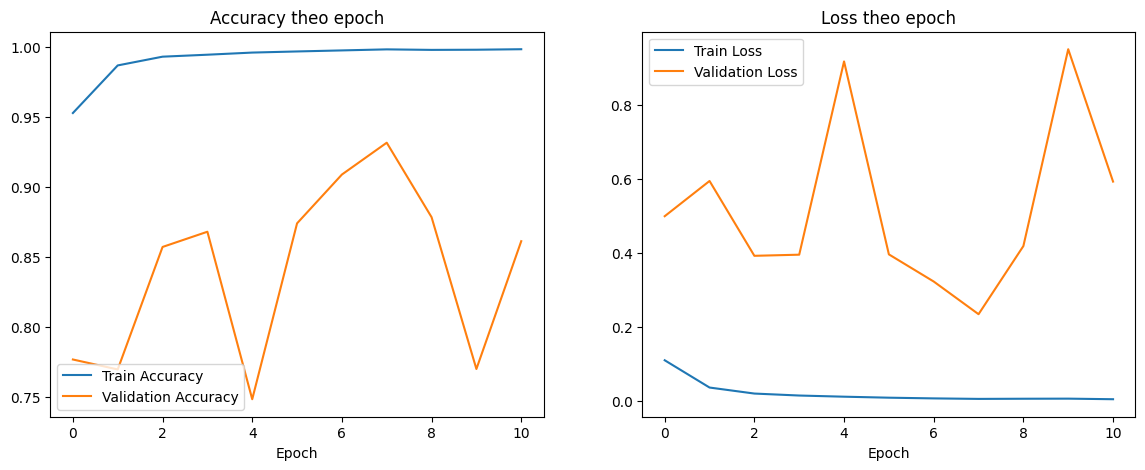

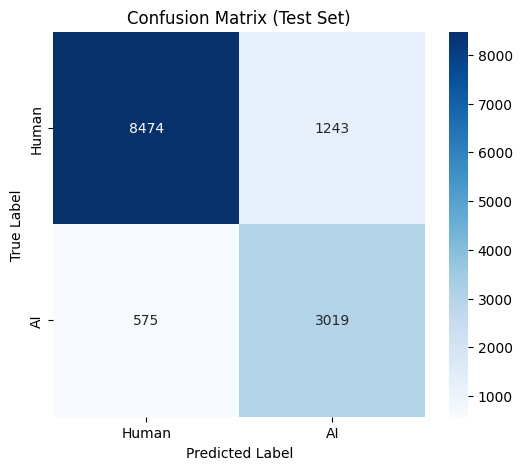

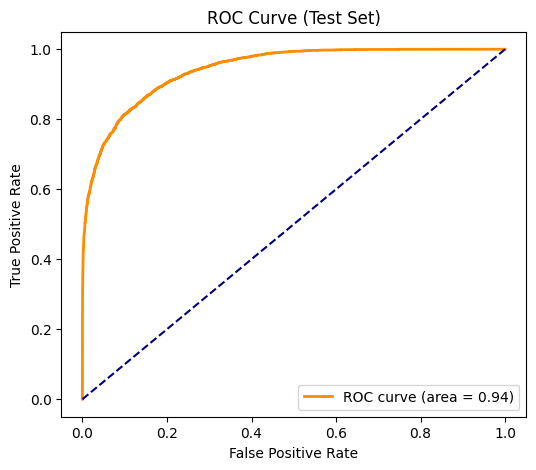

In [7]:
history = best_history_final

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(history["train_acc"], label="Train Accuracy"); ax1.plot(history["val_acc"], label="Validation Accuracy")
ax1.set_title("Accuracy theo epoch"); ax1.set_xlabel("Epoch"); ax1.legend()
ax2.plot(history["train_loss"], label="Train Loss"); ax2.plot(history["val_loss"], label="Validation Loss")
ax2.set_title("Loss theo epoch"); ax2.set_xlabel("Epoch"); ax2.legend()
plt.show()

cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Human", "AI"], yticklabels=["Human", "AI"])
plt.xlabel("Predicted Label"); plt.ylabel("True Label"); plt.title("Confusion Matrix (Test Set)")
plt.show()

fpr, tpr, _ = roc_curve(y_test, y_test_score)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (area = {auc(fpr, tpr):.2f})")
plt.plot([0, 1], [0, 1], color="navy", linestyle="--")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve (Test Set)")
plt.legend(loc="lower right"); plt.show()

In [8]:
def save_results(name, file, y_true, y_pred, y_score, train_acc, val_acc, train_time, infer_time, best_params, history=None):
    """Lưu kết quả để notebook so sánh đọc lại."""
    fpr, tpr, _ = roc_curve(y_true, y_score)
    result = {
        "model": name,
        "best_params": str(best_params),
        "train_acc": float(train_acc),
        "val_acc": float(val_acc),
        "test_acc": float(accuracy_score(y_true, y_pred)),
        "roc_auc": float(auc(fpr, tpr)),
        "train_time_s": float(train_time),
        "infer_time_s": float(infer_time),
        "report": classification_report(y_true, y_pred, target_names=["Human", "AI"], output_dict=True),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
        "fpr": fpr.tolist(),
        "tpr": tpr.tolist(),
        "history": history,
    }
    with open(RESULTS_DIR / file, "w", encoding="utf-8") as f:
        json.dump(result, f, ensure_ascii=False)
    print(f"Đã lưu kết quả: {RESULTS_DIR / file}")

best_epoch = int(np.argmax(best_history_final["val_acc"]))
save_results("TextCNN", "results_cnn.json", y_test, y_test_pred, y_test_score,
             best_history_final["train_acc"][best_epoch], best_overall_acc, grid_time, infer_time,
             best_config, history=best_history_final)

Đã lưu kết quả: /content/drive/MyDrive/NLP/results/results_cnn.json
